## Importando a biblioteca Pandas
Sabemos que para importar um biblioteca usamos o comando **`import`** e caso se queira dar um nome diferente usamos a **`as`** veja no código baixo:

In [47]:
import pandas as pd #importando a biblioteca pandas
#importando outras bibliotecas que serão usadas.
import numpy as np
import requests
import json
import sqlalchemy
from sqlalchemy import create_engine, MetaData, Table, inspect
import lxml
import matplotlib.pyplot as plt

## Estruturas Básicas em Pandas
1. `Series`: com uma unica dimensão como vetores de qualquer tipo, inteiros, strings ou objetos.
2. `DataFrame`: com duas dimensões como uma matris de quyalquer tipo, é basicamente uma tabela com linhas e colunas.
## Criando um Objeto
Abaixo alguns exemplos criando objetos e exportando eles.

In [145]:
s = pd.Series([1, 3, 5, np.nan, 6, 8])
s

0    1.0
1    3.0
2    5.0
3    NaN
4    6.0
5    8.0
dtype: float64

Criando um DataFrame a partir de uma matriz.

In [265]:
dates = pd.date_range("20261014",periods=6)
df = pd.DataFrame(np.random.randn(6, 4), index=dates, columns=list("ABCD"))
df

,A,B,C,D
2026-10-14,0.461352,0.472691,-1.602555,-0.980897
2026-10-15,-1.790039,1.165476,0.973317,-0.861727
2026-10-16,1.927494,1.530011,1.522398,1.416642
2026-10-17,1.399534,-1.444001,-0.515519,0.354241
2026-10-18,0.080345,0.066002,-0.983461,1.079033
2026-10-19,0.700729,-0.226667,-0.338802,-1.846188


Criando um DataFrame a partir de um dicionário.

In [150]:
df2 = pd.DataFrame(
    {
        "A":1.0,
        "B": pd.Timestamp("20261014"),
        "C": pd.Series(1, index=list(range(4)),dtype="float32"),
        "D": np.array([3]*4,dtype="int32"),
        "E": pd.Categorical(["test","train", "test", "train"]),
        "F":"foo",
    }
)
df2

,A,B,C,D,E,F
0,1.0,2026-10-14,1.0,3,test,foo
1,1.0,2026-10-14,1.0,3,train,foo
2,1.0,2026-10-14,1.0,3,test,foo
3,1.0,2026-10-14,1.0,3,train,foo


Veja como um dataframe pode ser composto por dados de diferentes tipos:

In [157]:
df2.dtypes

A           float64
B    datetime64[us]
C           float32
D             int32
E          category
F               str
dtype: object

## Importando os dados
Para realizar a importação de dados temos algumas formas que serão listadas respectivamente:
<ul>
    <li>Importando de um arquivo .xlsx</li>
    <li>Importando de um arquivo .csv</li>
    <li>Importando de um arquivo .csv em um link</li>
</ul>

In [2]:
#importando de um arquivo .xlsx
xlsx = pd.ExcelFile('dados_vendas.xlsx')#aqui coloca-se o nome do arquivo
#Lembre-se de colocar o caminha completo se não estiver no mesmo diretorio do código
df3 = pd.read_excel(xlsx, 'Pasta1') #Neste exemplo nossos dados estão na 'Pasta1'
#Atente-se para o nome da planilha onde estão os dados, pois um arquivo pode conter muitas planilhas

In [3]:
#Para ler arquivos CSV codificados em ISO
df4 = pd.read_csv('Credit.csv')
#Lembre-se de colocar o caminha completo se não estiver no mesmo diretorio do código

### Parametros da função para arquivos .csv
<table style="width:100%">
    <tr>
        <th style="width:10%">Parâmetro</th>
        <th>Para que serve?</th>
        <th>Exemplo de Código</th>
    </tr>
    <tr>
        <td style="width:10%">sep ou delimiter</td>
        <td>Define o caractere que separa as colunas. O padrão é a vírgula (,). Muito útil usar ; para arquivos brasileiros.</td>
        <td>pd.read_csv('dados.csv', sep=';')</td>
    </tr>
    <tr>
        <td style="width:10%">encoding</td>
        <Td>Define a codificação de caracteres. Use latin-1 ou utf-8 se o seu arquivo tiver acentos ou caracteres especiais quebrados.</Td>
        <td>pd.read_csv('dados.csv', encoding='latin-1')</td>
    </tr>
    <tr>
        <td style="width:10%">usecols</td>
        <td>Carrega apenas as colunas que você especificar, economizando memória.</td>
        <td>pd.read_csv('dados.csv', usecols=['Nome', 'Idade'])</td>
    </tr>
	<tr>
        <td>nrows</td>
        <td>Limita a quantidade de linhas lidas (ótimo para testar arquivos gigantes).</td>
        <td>pd.read_csv('dados.csv', nrows=100)</td>
    </tr>
    <tr>
        <td style="width:10%">parse_dates</td>
        <td>Converte colunas de texto com datas diretamente no formato de data (datetime) do Python.</td>
        <td>pd.read_csv('dados.csv', parse_dates=['Data_Venda'])</td>
    </tr>
    <tr>
        <td style="width:10%">decimal</td>
        <td>Altera o separador decimal. No Brasil, usamos a vírgula (,) para decimais em vez de ponto (.).</td>
        <td>pd.read_csv('dados.csv', decimal=',')</td>
    </tr>
</table>

In [4]:
#Caso queira pegar um arquivo que esteja em um link basta então somente colocar a url no lugar do arquivo
url = 'https://raw.githubusercontent.com/alura-cursos/pandas/main/superstore_data.csv' #salvando em uma variável para organizar melhor.
dados_superstore = pd.read_csv(url)

## Visualização dos dados

Agora esta na hora de visualizarmos esses dados.
Primeiro  vamos mostrar apenas as 5 primeiras linhas do nosso datafreme com o comando `.head()`

In [5]:
df3.head() #Observe que quando pegamos um dataframe(df) com menos que 5 linhas ele mostra todas as linhas que tem no df

,ID_Pedido,Data,Produto,Categoria,Quantidade,Valor_Unitario,Regiao
0,1,2026-01-10,Notebook,Eletrônicos,1,3500,Sudeste
1,2,2026-01-11,Smartphone,Eletrônicos,2,1200,Nordeste
2,3,2026-01-12,Cadeira Gamer,Móveis,2,850,Sul
3,4,2026-01-13,"Monitor 24""",Eletrônicos,2,900,Sudeste
4,5,2026-01-14,Mesa Escritório,Móveis,2,450,Centro-Oeste


In [6]:
df4.head() #Quando o df é maior ele mostra apenas as 5 primeiras linhas com todas as colunas.

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,'critical/other existing credit',radio/tv,1169,'no known savings',>=7,4,'male single',none,...,'real estate',67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,'existing paid',radio/tv,5951,<100,1<=X<4,2,'female div/dep/mar',none,...,'real estate',22,none,own,1,skilled,1,none,yes,bad
2,'no checking',12,'critical/other existing credit',education,2096,<100,4<=X<7,2,'male single',none,...,'real estate',49,none,own,1,'unskilled resident',2,none,yes,good
3,<0,42,'existing paid',furniture/equipment,7882,<100,4<=X<7,2,'male single',guarantor,...,'life insurance',45,none,'for free',1,skilled,2,none,yes,good
4,<0,24,'delayed previously','new car',4870,<100,1<=X<4,3,'male single',none,...,'no known property',53,none,'for free',2,skilled,2,none,yes,bad


In [7]:
dados_superstore.head() # Veja outro exemplo

,Id,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Response,Complain
0,1826,1970,Graduation,Divorced,84835.0,0,0,6/16/2014,0,189,...,111,189,218,1,4,4,6,1,1,0
1,1,1961,Graduation,Single,57091.0,0,0,6/15/2014,0,464,...,7,0,37,1,7,3,7,5,1,0
2,10476,1958,Graduation,Married,67267.0,0,1,5/13/2014,0,134,...,15,2,30,1,3,2,5,2,0,0
3,1386,1967,Graduation,Together,32474.0,1,1,11/5/2014,0,10,...,0,0,0,1,1,0,2,7,0,0
4,5371,1989,Graduation,Single,21474.0,1,0,8/4/2014,0,6,...,11,0,34,2,3,1,2,7,1,0


Agora vamos usar o comando `.tail(x)` para mostrar a quantidade que quisermos de linhas finais.  
Vejamos um exemplo mostrando as 3 ultimas linhas.

In [162]:
dados_superstore.tail(3)

,Id,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Response,Complain
2237,22,1976,Graduation,Divorced,46310.0,1,0,3/12/2012,99,185,...,15,5,14,2,6,1,5,8,0,0
2238,528,1978,Graduation,Married,65819.0,0,0,11/29/2012,99,267,...,149,165,63,1,5,4,10,3,0,0
2239,4070,1969,PhD,Married,94871.0,0,2,1/9/2012,99,169,...,188,0,144,1,8,5,4,7,1,0


Para mostrar as linhas e colunas usamos `.index` e `.columns` respectivamente. Vejamos um exemplo:

In [166]:
#Mostra todos os index (linhas) do DataFrame
df.index

DatetimeIndex(['2026-10-14', '2026-10-15', '2026-10-16', '2026-10-17',
               '2026-10-18', '2026-10-19'],
              dtype='datetime64[us]', freq='D')

In [164]:
#Mostra todas as colinas do DataFrame
df.columns

Index(['A', 'B', 'C', 'D'], dtype='str')

In [ ]:
#Quantidade de linhas e colunas do DataFrame
df.shape

Aqui estão algumas outras funções que podem ser úteis:

In [169]:
#Resumo estatístico do DataFrame, com quartis, mediana, etc.
df.describe() # descreve detalhes sobre cada uma das colunas como contagem de itens, média, etc.

,A,B,C,D
count,6.000000,6.000000,6.000000,6.000000
mean,0.007646,0.283796,0.531989,0.046813
std,0.992945,0.945905,1.540867,0.568787
min,-1.050743,-0.995418,-0.952195,-0.519460
25%,-0.825293,-0.481891,-0.539799,-0.426070
50%,0.058201,0.622499,-0.065765,-0.083814
75%,0.427878,0.981742,1.610434,0.550726
max,1.548906,1.201730,2.804301,0.745882


In [170]:
df.sort_index(axis=1, ascending=False)#ordena os valores pelo index sendo axis 1 para coluna e 0 para linhas

,D,C,B,A
2026-10-14,0.745882,-0.952195,0.941294,0.339215
2026-10-15,0.077675,2.046728,1.201730,-1.026119
2026-10-16,-0.245302,-0.433083,0.303704,-0.222813
2026-10-17,-0.519460,0.301552,-0.743757,-1.050743
2026-10-18,-0.486326,2.804301,0.995225,1.548906
2026-10-19,0.708409,-0.575371,-0.995418,0.457432


In [171]:
df.sort_values(by="B") # ordena os valores pela coluna especificada no comando by

,A,B,C,D
2026-10-19,0.457432,-0.995418,-0.575371,0.708409
2026-10-18,1.548906,0.995225,2.804301,-0.486326
2026-10-17,-1.050743,-0.743757,0.301552,-0.519460
2026-10-16,-0.222813,0.303704,-0.433083,-0.245302
2026-10-15,-1.026119,1.201730,2.046728,0.077675
2026-10-14,0.339215,0.941294,-0.952195,0.745882


In [266]:
#Ordenando o df pela coluna "Valor_Unitario" em ordem crescente
df.sort_values(by="C")

,A,B,C,D
2026-10-14,0.461352,0.472691,-1.602555,-0.980897
2026-10-18,0.080345,0.066002,-0.983461,1.079033
2026-10-17,1.399534,-1.444001,-0.515519,0.354241
2026-10-19,0.700729,-0.226667,-0.338802,-1.846188
2026-10-15,-1.790039,1.165476,0.973317,-0.861727
2026-10-16,1.927494,1.530011,1.522398,1.416642


In [267]:
#Ordenando o df pela coluna "Valor_Unitario" em ordem decrescente
df.sort_values(by="C", ascending=False)

,A,B,C,D
2026-10-16,1.927494,1.530011,1.522398,1.416642
2026-10-15,-1.790039,1.165476,0.973317,-0.861727
2026-10-19,0.700729,-0.226667,-0.338802,-1.846188
2026-10-17,1.399534,-1.444001,-0.515519,0.354241
2026-10-18,0.080345,0.066002,-0.983461,1.079033
2026-10-14,0.461352,0.472691,-1.602555,-0.980897


In [180]:
df.T # Transpoem o DataFrame invertendo coluna e linha.

,2026-10-14,2026-10-15,2026-10-16,2026-10-17,2026-10-18,2026-10-19
A,0.339215,-1.026119,-0.222813,-1.050743,1.548906,0.457432
B,0.941294,1.201730,0.303704,-0.743757,0.995225,-0.995418
C,-0.952195,2.046728,-0.433083,0.301552,2.804301,-0.575371
D,0.745882,0.077675,-0.245302,-0.519460,-0.486326,0.708409


## Conversão de Data Frame
Para trazer um **`dataframe`** de volta para o tipo **`numpy`** por exemplo usamos:

In [167]:
df.to_numpy()

array([[ 0.33921495,  0.94129382, -0.95219477,  0.74588202],
       [-1.02611894,  1.20173015,  2.04672824,  0.0776751 ],
       [-0.22281318,  0.303704  , -0.43308262, -0.24530221],
       [-1.05074256, -0.74375658,  0.30155238, -0.51946012],
       [ 1.54890603,  0.99522493,  2.80430098, -0.48632603],
       [ 0.4574319 , -0.99541773, -0.57537075,  0.70840915]])

## Selecionando itens no DataFrame
Existem muitas maneiras de selecionar itens de um DataFrame, a baixo desmonstraremos todos.

In [179]:
df["A"] #Selecionando um coluna usando []

2026-10-14    0.339215
2026-10-15   -1.026119
2026-10-16   -0.222813
2026-10-17   -1.050743
2026-10-18    1.548906
2026-10-19    0.457432
Freq: D, Name: A, dtype: float64

In [181]:
df.A #Selecionando uma coluna sem usar o []

2026-10-14    0.339215
2026-10-15   -1.026119
2026-10-16   -0.222813
2026-10-17   -1.050743
2026-10-18    1.548906
2026-10-19    0.457432
Freq: D, Name: A, dtype: float64

In [186]:
df[["B","A","C"]] #Selecionando mais de uma coluna com o []

,B,A,C
2026-10-14,0.941294,0.339215,-0.952195
2026-10-15,1.201730,-1.026119,2.046728
2026-10-16,0.303704,-0.222813,-0.433083
2026-10-17,-0.743757,-1.050743,0.301552
2026-10-18,0.995225,1.548906,2.804301
2026-10-19,-0.995418,0.457432,-0.575371


In [188]:
df[0:3]#Selecionando um grupo de linhas

,A,B,C,D
2026-10-14,0.339215,0.941294,-0.952195,0.745882
2026-10-15,-1.026119,1.201730,2.046728,0.077675
2026-10-16,-0.222813,0.303704,-0.433083,-0.245302


## Selecionando por Posição
Outra forma de selecionar uma coluna inteira é usar a função `.iloc` e `.iat`

In [198]:
df.iloc[3]# Pegando uma linha específica

A   -1.050743
B   -0.743757
C    0.301552
D   -0.519460
Name: 2026-10-17 00:00:00, dtype: float64

In [191]:
df.iloc[3:5,0:2] # Pegar uma lista de elementos de posições especificas. 

,A,B
2026-10-17,-1.050743,-0.743757
2026-10-18,1.548906,0.995225


In [192]:
df.iloc[[1,2,4],[0,2]] # Pegar uma lista de elementos de posições especificas. 

,A,C
2026-10-15,-1.026119,2.046728
2026-10-16,-0.222813,-0.433083
2026-10-18,1.548906,2.804301


In [197]:
df.iloc[1:3,:] #Pegar todos os valores e linhas específicas

,A,B,C,D
2026-10-15,-1.026119,1.201730,2.046728,0.077675
2026-10-16,-0.222813,0.303704,-0.433083,-0.245302


In [193]:
df.iloc[:,1:3] #Pegar todos os valores e colunas específicas

,B,C
2026-10-14,0.941294,-0.952195
2026-10-15,1.201730,2.046728
2026-10-16,0.303704,-0.433083
2026-10-17,-0.743757,0.301552
2026-10-18,0.995225,2.804301
2026-10-19,-0.995418,-0.575371


In [194]:
df.iloc[1,1] #Para pegar um valor específico

np.float64(1.2017301531607445)

In [ ]:
df.iat[1:1]#Para pegar um elemento específico mais rápido

## Selecionando Valores pelo Booleano
Veja alguns exemplos:

In [199]:
df[df["A"]>0]

,A,B,C,D
2026-10-14,0.339215,0.941294,-0.952195,0.745882
2026-10-18,1.548906,0.995225,2.804301,-0.486326
2026-10-19,0.457432,-0.995418,-0.575371,0.708409


In [200]:
df[df>0]

,A,B,C,D
2026-10-14,0.339215,0.941294,NaN,0.745882
2026-10-15,NaN,1.201730,2.046728,0.077675
2026-10-16,NaN,0.303704,NaN,NaN
2026-10-17,NaN,NaN,0.301552,NaN
2026-10-18,1.548906,0.995225,2.804301,NaN
2026-10-19,0.457432,NaN,NaN,0.708409


In [107]:
#Filtrando o DataFrame para mostrar apenas valores pares
df[df['ID_Pedido'] % 2 == 0]

,ID_Pedido,Data,Produto,Categoria,Quantidade,Valor_Unitario,Regiao,Total
1,2,2026-01-11,Smartphone,Eletrônicos,2,1200,Nordeste,0
3,4,2026-01-13,"Monitor 24""",Eletrônicos,2,900,Sudeste,0
5,6,2026-01-15,Teclado Mecânico,Acessórios,1,250,Norte,0


Agora vamos criar um exemplo:

In [201]:
df5 = df.copy()
df5["E"] = ["one", "one", "two", "three", "four", "three"]
df5

,A,B,C,D,E
2026-10-14,0.339215,0.941294,-0.952195,0.745882,one
2026-10-15,-1.026119,1.201730,2.046728,0.077675,one
2026-10-16,-0.222813,0.303704,-0.433083,-0.245302,two
2026-10-17,-1.050743,-0.743757,0.301552,-0.519460,three
2026-10-18,1.548906,0.995225,2.804301,-0.486326,four
2026-10-19,0.457432,-0.995418,-0.575371,0.708409,three


In [203]:
df5[df5["E"].isin(["two", "four"])]

,A,B,C,D,E
2026-10-16,-0.222813,0.303704,-0.433083,-0.245302,two
2026-10-18,1.548906,0.995225,2.804301,-0.486326,four


## Inserindo mais dados
Veja agora como colocar novas colunas em um dataframe e até mudar dados específicos:

In [216]:
s1 = pd.Series([1, 2, 3, 4, 5, 6],index=pd.date_range("20261015", periods=6))
df["F"] = s1 #Criando um nova coluna inteira
df.at[dates[0], "A"] = 0 #Inserindo um novo valor e uma posição específica
df.iat[0, 1] = 0 #Inserindo um valor em uma posição específica
df.loc[:, "D"] = np.array([5] * len(df)) #Criando uma nova coluna.
df

,A,B,C,D,F
2026-10-14,0.000000,0.000000,-0.952195,5.0,NaN
2026-10-15,-1.026119,1.201730,2.046728,5.0,1.0
2026-10-16,-0.222813,0.303704,-0.433083,5.0,2.0
2026-10-17,-1.050743,-0.743757,0.301552,5.0,3.0
2026-10-18,1.548906,0.995225,2.804301,5.0,4.0
2026-10-19,0.457432,-0.995418,-0.575371,5.0,5.0


In [217]:
df2 = df.copy()
df2[df2 > 0] = -df2
df2

,A,B,C,D,F
2026-10-14,0.000000,0.000000,-0.952195,-5.0,NaN
2026-10-15,-1.026119,-1.201730,-2.046728,-5.0,-1.0
2026-10-16,-0.222813,-0.303704,-0.433083,-5.0,-2.0
2026-10-17,-1.050743,-0.743757,-0.301552,-5.0,-3.0
2026-10-18,-1.548906,-0.995225,-2.804301,-5.0,-4.0
2026-10-19,-0.457432,-0.995418,-0.575371,-5.0,-5.0


## Lidando com os valores nulos
Lidando com números nulos

In [218]:
df1 = df.reindex(index=dates[0:4], columns=list(df.columns) + ["E"])
df1.loc[dates[0] : dates[1], "E"] = 1
df1

,A,B,C,D,F,E
2026-10-14,0.000000,0.000000,-0.952195,5.0,NaN,1.0
2026-10-15,-1.026119,1.201730,2.046728,5.0,1.0,1.0
2026-10-16,-0.222813,0.303704,-0.433083,5.0,2.0,NaN
2026-10-17,-1.050743,-0.743757,0.301552,5.0,3.0,NaN


In [219]:
#Deve-se ter em mente que se o valor axis for 0 as linhas com nulos seram deletadas.
#Se axis for 1 as colunas que serão deletadas.
#Se o argumento how for "any" então caso a linha ou coluna tenha pelo menos um valor nulo ela será deletada.
#Se o argumento how for "all" então somente caso a linha ou a coluna tenha todos os valores nulos será deletada.
df1.dropna(axis=0, how="any")

,A,B,C,D,F,E
2026-10-15,-1.026119,1.20173,2.046728,5.0,1.0,1.0


In [222]:
df1.fillna(value=7)

,A,B,C,D,F,E
2026-10-14,0.000000,0.000000,-0.952195,5.0,7.0,1.0
2026-10-15,-1.026119,1.201730,2.046728,5.0,1.0,1.0
2026-10-16,-0.222813,0.303704,-0.433083,5.0,2.0,7.0
2026-10-17,-1.050743,-0.743757,0.301552,5.0,3.0,7.0


In [221]:
pd.isna(df1)

,A,B,C,D,F,E
2026-10-14,False,False,False,False,True,False
2026-10-15,False,False,False,False,False,False
2026-10-16,False,False,False,False,False,True
2026-10-17,False,False,False,False,False,True


## Veja como eliminar determinados dados do DataFrame

In [42]:
#Removendo linhas pelo index
df.drop([0, 1])# Para salvar temos que atribuir isso a uma variável

,ID_Pedido,Data,Produto,Categoria,Quantidade,Valor_Unitario,Regiao
2,3,2026-01-12,Cadeira Gamer,Móveis,2,850,Sul
3,4,2026-01-13,"Monitor 24""",Eletrônicos,2,900,Sudeste
4,5,2026-01-14,Mesa Escritório,Móveis,2,450,Centro-Oeste
5,6,2026-01-15,Teclado Mecânico,Acessórios,1,250,Norte


In [43]:
#Removendo colunas utilizando o argumento axis=1
df.drop('Quantidade', axis=1) # Para salvar temos que atribuir isso a uma variável

,ID_Pedido,Data,Produto,Categoria,Valor_Unitario,Regiao
0,1,2026-01-10,Notebook,Eletrônicos,3500,Sudeste
1,2,2026-01-11,Smartphone,Eletrônicos,1200,Nordeste
2,3,2026-01-12,Cadeira Gamer,Móveis,850,Sul
3,4,2026-01-13,"Monitor 24""",Eletrônicos,900,Sudeste
4,5,2026-01-14,Mesa Escritório,Móveis,450,Centro-Oeste
5,6,2026-01-15,Teclado Mecânico,Acessórios,250,Norte


In [44]:
df  #Como não atribuimos as operações anteriores a variável df ela continua com o df original

,ID_Pedido,Data,Produto,Categoria,Quantidade,Valor_Unitario,Regiao
0,1,2026-01-10,Notebook,Eletrônicos,1,3500,Sudeste
1,2,2026-01-11,Smartphone,Eletrônicos,2,1200,Nordeste
2,3,2026-01-12,Cadeira Gamer,Móveis,2,850,Sul
3,4,2026-01-13,"Monitor 24""",Eletrônicos,2,900,Sudeste
4,5,2026-01-14,Mesa Escritório,Móveis,2,450,Centro-Oeste
5,6,2026-01-15,Teclado Mecânico,Acessórios,1,250,Norte


## Operações

### Operações com Series usando Pandas

In [104]:
s = pd.Series([1, 2, 3, 4, 5], index=['a', 'b', 'c', 'd', 'e'])
s

a    1
b    2
c    3
d    4
e    5
dtype: int64

In [100]:
#Somando todos os valores presentes na Series por 2
s.add(2)

a    3
b    4
c    5
d    6
e    7
dtype: int64

In [101]:
#Subtraindo 2 de todos os valores
s.sub(2)

a   -1
b    0
c    1
d    2
e    3
dtype: int64

In [102]:
#Multiplicando todos os valores por 2
s.mul(2)

a     2
b     4
c     6
d     8
e    10
dtype: int64

In [103]:
#Dividindo valores por 2
s.div(2)

a    0.5
b    1.0
c    1.5
d    2.0
e    2.5
dtype: float64

### Operações Simples com o DataFrame

In [223]:
#Contagem de dados não-nulos
df.count()

A    6
B    6
C    6
D    6
F    5
dtype: int64

In [226]:
#Renomeando colunas de um DataFrame:
#Se seu DataFrame possui 3 colunas, passe 3 novos valores em uma lista
df.columns = ['A', 'Categoria','Valor_Unitario', 'Regiao', "Total"]
df.columns

Index(['A', 'Categoria', 'Valor_Unitario', 'Regiao', 'Total'], dtype='str')

In [227]:
#Renomeando colunas de um DataFrame:
#Se seu DataFrame possui 3 colunas, passe 3 novos valores em uma lista
df.columns = ['A', 'B','C', 'D', "F"]
df.columns

Index(['A', 'B', 'C', 'D', 'F'], dtype='str')

In [228]:
#Soma dos valores de uma coluna de um DataFrame
df.sum()

A    -0.293337
B     0.761485
C     3.191933
D    30.000000
F    15.000000
dtype: float64

In [229]:
#Soma dos valores das colunas que contém números em um DataFrame
df.select_dtypes(include='number').sum()

A    -0.293337
B     0.761485
C     3.191933
D    30.000000
F    15.000000
dtype: float64

In [230]:
#Menor valor de um DataFrame
df.min()

A   -1.050743
B   -0.995418
C   -0.952195
D    5.000000
F    1.000000
dtype: float64

In [231]:
#Maior valor
df.max()

A    1.548906
B    1.201730
C    2.804301
D    5.000000
F    5.000000
dtype: float64

In [232]:
#Index do menor valor
df.idxmin()

A   2026-10-17
B   2026-10-19
C   2026-10-14
D   2026-10-14
F   2026-10-15
dtype: datetime64[us]

In [233]:
#Index do maior valor
df.idxmax()

A   2026-10-18
B   2026-10-15
C   2026-10-18
D   2026-10-14
F   2026-10-19
dtype: datetime64[us]

### Operações estatisticas com DataFrame

In [234]:
#Média dos valores
df.mean()

A   -0.048889
B    0.126914
C    0.531989
D    5.000000
F    3.000000
dtype: float64

In [235]:
#Média dos valores de cada linha
df.mean(axis=1)

2026-10-14    1.011951
2026-10-15    1.644468
2026-10-16    1.329562
2026-10-17    1.301411
2026-10-18    2.869686
2026-10-19    1.777329
Freq: D, dtype: float64

In [237]:
#Mediana dos valores
df.median()

A   -0.111407
B    0.151852
C   -0.065765
D    5.000000
F    3.000000
dtype: float64

In [244]:
s = pd.Series([1, 3, 5, np.nan, 6, 8], index=dates).shift(2)
s

2026-10-14    NaN
2026-10-15    NaN
2026-10-16    1.0
2026-10-17    3.0
2026-10-18    5.0
2026-10-19    NaN
Freq: D, dtype: float64

In [245]:
df

,A,B,C,D,F
2026-10-14,0.000000,0.000000,-0.952195,5.0,NaN
2026-10-15,-1.026119,1.201730,2.046728,5.0,1.0
2026-10-16,-0.222813,0.303704,-0.433083,5.0,2.0
2026-10-17,-1.050743,-0.743757,0.301552,5.0,3.0
2026-10-18,1.548906,0.995225,2.804301,5.0,4.0
2026-10-19,0.457432,-0.995418,-0.575371,5.0,5.0


In [246]:
df.sub(s, axis="index")

,A,B,C,D,F
2026-10-14,NaN,NaN,NaN,NaN,NaN
2026-10-15,NaN,NaN,NaN,NaN,NaN
2026-10-16,-1.222813,-0.696296,-1.433083,4.0,1.0
2026-10-17,-4.050743,-3.743757,-2.698448,2.0,0.0
2026-10-18,-3.451094,-4.004775,-2.195699,0.0,-1.0
2026-10-19,NaN,NaN,NaN,NaN,NaN


### Usando funções em DataFrames

In [247]:
#Aplicando uma função que substitui a por b
df.apply(lambda x: x.replace('a','b'))

,A,B,C,D,F
2026-10-14,0.000000,0.000000,-0.952195,5.0,NaN
2026-10-15,-1.026119,1.201730,2.046728,5.0,1.0
2026-10-16,-0.222813,0.303704,-0.433083,5.0,2.0
2026-10-17,-1.050743,-0.743757,0.301552,5.0,3.0
2026-10-18,1.548906,0.995225,2.804301,5.0,4.0
2026-10-19,0.457432,-0.995418,-0.575371,5.0,5.0


In [248]:
df.agg(lambda x: np.mean(x) * 5.6)

A    -0.273781
B     0.710719
C     2.979138
D    28.000000
F    16.800000
dtype: float64

In [249]:
df.transform(lambda x: x * 101.2)

,A,B,C,D,F
2026-10-14,0.000000,0.000000,-96.362110,506.0,NaN
2026-10-15,-103.843237,121.615091,207.128898,506.0,101.2
2026-10-16,-22.548694,30.734845,-43.827962,506.0,202.4
2026-10-17,-106.335147,-75.268166,30.517101,506.0,303.6
2026-10-18,156.749290,100.716763,283.795259,506.0,404.8
2026-10-19,46.292108,-100.736275,-58.227520,506.0,506.0


### Contando Valores em Séries Pandas

In [250]:
s = pd.Series(np.random.randint(0, 7, size=10))
s

0    4
1    5
2    1
3    0
4    4
5    4
6    4
7    1
8    4
9    3
dtype: int32

In [251]:
s.value_counts()

4    5
1    2
5    1
0    1
3    1
Name: count, dtype: int64

### Usando Métodos de Strings

In [252]:
s = pd.Series(["A", "B", "C", "Aaba", "Baca", np.nan, "CABA", "dog", "cat"])
s.str.lower()

0       a
1       b
2       c
3    aaba
4    baca
5     NaN
6    caba
7     dog
8     cat
dtype: str

In [253]:
s.str.upper()

0       A
1       B
2       C
3    AABA
4    BACA
5     NaN
6    CABA
7     DOG
8     CAT
dtype: str

## Juntando DataFrames

### Concatenando DataFrames

In [254]:
df = pd.DataFrame(np.random.randn(10, 4))
df

,0,1,2,3
0,-2.137237,0.944214,-0.768184,-0.495685
1,-0.976421,-0.294969,0.437593,-0.535044
2,0.867263,-0.518255,0.457831,-1.274514
3,0.880660,1.173514,-0.230525,0.102550
4,-2.850050,0.360870,-0.404513,0.608457
5,-0.847394,0.615708,0.998882,0.636584
6,0.409683,-0.079317,0.940779,0.635753
7,-1.137590,1.123831,-0.124492,1.223120
8,-1.352308,0.604559,0.811159,-0.245364
9,0.340602,0.277058,-0.919174,0.303955


In [255]:
pieces = [df[:3], df[3:7], df[7:]]
pd.concat(pieces)

,0,1,2,3
0,-2.137237,0.944214,-0.768184,-0.495685
1,-0.976421,-0.294969,0.437593,-0.535044
2,0.867263,-0.518255,0.457831,-1.274514
3,0.880660,1.173514,-0.230525,0.102550
4,-2.850050,0.360870,-0.404513,0.608457
5,-0.847394,0.615708,0.998882,0.636584
6,0.409683,-0.079317,0.940779,0.635753
7,-1.137590,1.123831,-0.124492,1.223120
8,-1.352308,0.604559,0.811159,-0.245364
9,0.340602,0.277058,-0.919174,0.303955


### Usando a função Join

In [257]:
left = pd.DataFrame({"key": ["foo", "foo"], "lval": [1, 2]})
right = pd.DataFrame({"key": ["foo", "foo"], "rval": [4, 5]})
left

,key,lval
0,foo,1
1,foo,2


In [258]:
right

,key,rval
0,foo,4
1,foo,5


In [259]:
pd.merge(left, right, on="key")

,key,lval,rval
0,foo,1,4
1,foo,1,5
2,foo,2,4
3,foo,2,5


In [260]:
left = pd.DataFrame({"key": ["foo", "bar"], "lval": [1, 2]})
right = pd.DataFrame({"key": ["foo", "bar"], "rval": [4, 5]})
left

,key,lval
0,foo,1
1,bar,2


In [261]:
right

,key,rval
0,foo,4
1,bar,5


In [262]:
pd.merge(left, right, on="key")

,key,lval,rval
0,foo,1,4
1,bar,2,5


### Usando os agrupamentos da função `groupby()`

In [268]:
df = pd.DataFrame(
    {
        "A": ["foo", "bar", "foo", "bar", "foo", "bar", "foo", "foo"],
        "B": ["one", "one", "two", "three", "two", "two", "one", "three"],
        "C": np.random.randn(8),
        "D": np.random.randn(8),
    }
)
df

,A,B,C,D
0,foo,one,0.611169,-1.455755
1,bar,one,0.146981,-0.498553
2,foo,two,-0.440362,0.012675
3,bar,three,-1.063519,1.228655
4,foo,two,-1.118463,-0.977304
5,bar,two,-0.370977,0.490505
6,foo,one,-0.190177,0.671455
7,foo,three,-1.037489,0.812618


In [269]:
df.groupby("A")[["C", "D"]].sum()

,C,D
A,,
bar,-1.287515,1.220607
foo,-2.175322,-0.936311


In [270]:
df.groupby(["A", "B"]).sum()

C         D
A   B                        
bar one    0.146981 -0.498553
    three -1.063519  1.228655
    two   -0.370977  0.490505
foo one    0.420992 -0.784300
    three -1.037489  0.812618
    two   -1.558825 -0.964630

## MultiIndex e a função Stack e Pivot Table

### MultiIndex
O MultiIndex (ou índice multinível) é o recurso do Pandas que permite ter duas ou mais colunas atuando como índices ao mesmo tempo, criando uma estrutura hierárquica (uma categoria dentro de outra) tanto nas linhas quanto nas colunas.
Pense nele como uma estrutura de pastas no seu computador: você tem a pasta principal, as subpastas dentro dela e, por fim, os arquivos.

In [6]:
arrays = [
   ["bar", "bar", "baz", "baz", "foo", "foo", "qux", "qux"],
   ["one", "two", "one", "two", "one", "two", "one", "two"],
]

In [7]:
index = pd.MultiIndex.from_arrays(arrays, names=["first", "second"])
index

MultiIndex([('bar', 'one'),
            ('bar', 'two'),
            ('baz', 'one'),
            ('baz', 'two'),
            ('foo', 'one'),
            ('foo', 'two'),
            ('qux', 'one'),
            ('qux', 'two')],
           names=['first', 'second'])

In [8]:
df = pd.DataFrame(np.random.randn(8, 2), index=index, columns=["A", "B"])

In [9]:
df2 = df[:4]
df2

A         B
first second                    
bar   one     0.791746  0.976865
      two    -1.818856 -0.154164
baz   one     0.792105 -1.245428
      two     0.417295  0.659146

### Stack
A função `.stack()` no Pandas serve para "empilhar" as colunas de um DataFrame, transformando-as em linhas.
Ela pega os nomes das colunas e os joga para o índice, deixando o DataFrame com um formato mais "comprido" (longo) e vertical.

In [10]:
stacked = df2.stack()
stacked

first  second   
bar    one     A    0.791746
               B    0.976865
       two     A   -1.818856
               B   -0.154164
baz    one     A    0.792105
               B   -1.245428
       two     A    0.417295
               B    0.659146
dtype: float64

In [11]:
stacked.unstack()

A         B
first second                    
bar   one     0.791746  0.976865
      two    -1.818856 -0.154164
baz   one     0.792105 -1.245428
      two     0.417295  0.659146

In [12]:
stacked.unstack(1)

second        one       two
first                      
bar   A  0.791746 -1.818856
      B  0.976865 -0.154164
baz   A  0.792105  0.417295
      B -1.245428  0.659146

In [13]:
stacked.unstack(0)

first          bar       baz
second                      
one    A  0.791746  0.792105
       B  0.976865 -1.245428
two    A -1.818856  0.417295
       B -0.154164  0.659146

### Função Pivot Table
O `.pivot_table` (Tabela Dinâmica) no Pandas serve para resumir, agrupar e reorganizar uma tabela grande e confusa, transformando linhas comuns em novas colunas para facilitar a análise visual.  
É exatamente a mesma ferramenta conhecida como "Tabela Dinâmica" no Excel ou Google Sheets

In [14]:
df_ex = pd.DataFrame(
    {
        "Filial":["SP","SP", "RJ", "SP", "RJ"],
        "Produto": ["Notebook", "Smartphone", "Notebook", "Notebook", "Smartphone"],
        "Vendas": [5000, 3000, 4500, 1500, 2000],
    }
)
df_ex

,Filial,Produto,Vendas
0,SP,Notebook,5000
1,SP,Smartphone,3000
2,RJ,Notebook,4500
3,SP,Notebook,1500
4,RJ,Smartphone,2000


In [16]:
# Cria o pivot table
tabela_dinamica = pd.pivot_table(
    df_ex, 
    index='Filial',      # O que fica na vertical (linhas)
    columns='Produto',   # O que fica na horizontal (colunas)
    values='Vendas',     # O número que será calculado
    aggfunc='sum'        # O que fazer com os números repetidos (somar, tirar média, etc)
)
tabela_dinamica

Produto,Notebook,Smartphone
Filial,,
RJ,4500,2000
SP,6500,3000


In [17]:
df = pd.DataFrame(
    {
        "A": ["one", "one", "two", "three"] * 3,
        "B": ["A", "B", "C"] * 4,
        "C": ["foo", "foo", "foo", "bar", "bar", "bar"] * 2,
        "D": np.random.randn(12),
        "E": np.random.randn(12),
    }
)
df

,A,B,C,D,E
0,one,A,foo,-0.335439,-0.417201
1,one,B,foo,-0.365025,-0.174405
2,two,C,foo,-0.581886,1.510497
3,three,A,bar,0.181917,-0.590441
4,one,B,bar,-0.042880,-0.376792
5,one,C,bar,0.917479,-0.090317
6,two,A,foo,0.458324,1.885708
7,three,B,foo,0.343180,-0.583766
8,one,C,foo,-0.696626,-0.008188
9,one,A,bar,0.412481,-0.541426


In [18]:
pd.pivot_table(df, values="D", index=["A", "B"], columns=["C"])

C             bar       foo
A     B                    
one   A  0.412481 -0.335439
      B -0.042880 -0.365025
      C  0.917479 -0.696626
three A  0.181917       NaN
      B       NaN  0.343180
      C  0.849687       NaN
two   A       NaN  0.458324
      B  1.624657       NaN
      C       NaN -0.581886

## Séries temporais com pandas



In [19]:
rng = pd.date_range("1/1/2012", periods=100, freq="s")
rng

DatetimeIndex(['2012-01-01 00:00:00', '2012-01-01 00:00:01',
               '2012-01-01 00:00:02', '2012-01-01 00:00:03',
               '2012-01-01 00:00:04', '2012-01-01 00:00:05',
               '2012-01-01 00:00:06', '2012-01-01 00:00:07',
               '2012-01-01 00:00:08', '2012-01-01 00:00:09',
               '2012-01-01 00:00:10', '2012-01-01 00:00:11',
               '2012-01-01 00:00:12', '2012-01-01 00:00:13',
               '2012-01-01 00:00:14', '2012-01-01 00:00:15',
               '2012-01-01 00:00:16', '2012-01-01 00:00:17',
               '2012-01-01 00:00:18', '2012-01-01 00:00:19',
               '2012-01-01 00:00:20', '2012-01-01 00:00:21',
               '2012-01-01 00:00:22', '2012-01-01 00:00:23',
               '2012-01-01 00:00:24', '2012-01-01 00:00:25',
               '2012-01-01 00:00:26', '2012-01-01 00:00:27',
               '2012-01-01 00:00:28', '2012-01-01 00:00:29',
               '2012-01-01 00:00:30', '2012-01-01 00:00:31',
               '2012-01-

In [20]:
ts = pd.Series(np.random.randint(0, 500, len(rng)), index=rng)
ts

2012-01-01 00:00:00     84
2012-01-01 00:00:01    186
2012-01-01 00:00:02    195
2012-01-01 00:00:03    160
2012-01-01 00:00:04    110
                      ... 
2012-01-01 00:01:35    490
2012-01-01 00:01:36    448
2012-01-01 00:01:37     46
2012-01-01 00:01:38    208
2012-01-01 00:01:39    251
Freq: s, Length: 100, dtype: int32

In [21]:
ts.resample("5Min").sum()

2012-01-01    23907
Freq: 5min, dtype: int32

In [22]:
ts_utc = ts.tz_localize("UTC")
ts_utc

2012-01-01 00:00:00+00:00     84
2012-01-01 00:00:01+00:00    186
2012-01-01 00:00:02+00:00    195
2012-01-01 00:00:03+00:00    160
2012-01-01 00:00:04+00:00    110
                            ... 
2012-01-01 00:01:35+00:00    490
2012-01-01 00:01:36+00:00    448
2012-01-01 00:01:37+00:00     46
2012-01-01 00:01:38+00:00    208
2012-01-01 00:01:39+00:00    251
Freq: s, Length: 100, dtype: int32

In [23]:
ts_utc.tz_convert("US/Eastern")

2011-12-31 19:00:00-05:00     84
2011-12-31 19:00:01-05:00    186
2011-12-31 19:00:02-05:00    195
2011-12-31 19:00:03-05:00    160
2011-12-31 19:00:04-05:00    110
                            ... 
2011-12-31 19:01:35-05:00    490
2011-12-31 19:01:36-05:00    448
2011-12-31 19:01:37-05:00     46
2011-12-31 19:01:38-05:00    208
2011-12-31 19:01:39-05:00    251
Freq: s, Length: 100, dtype: int32

In [24]:
rng

DatetimeIndex(['2012-01-01 00:00:00', '2012-01-01 00:00:01',
               '2012-01-01 00:00:02', '2012-01-01 00:00:03',
               '2012-01-01 00:00:04', '2012-01-01 00:00:05',
               '2012-01-01 00:00:06', '2012-01-01 00:00:07',
               '2012-01-01 00:00:08', '2012-01-01 00:00:09',
               '2012-01-01 00:00:10', '2012-01-01 00:00:11',
               '2012-01-01 00:00:12', '2012-01-01 00:00:13',
               '2012-01-01 00:00:14', '2012-01-01 00:00:15',
               '2012-01-01 00:00:16', '2012-01-01 00:00:17',
               '2012-01-01 00:00:18', '2012-01-01 00:00:19',
               '2012-01-01 00:00:20', '2012-01-01 00:00:21',
               '2012-01-01 00:00:22', '2012-01-01 00:00:23',
               '2012-01-01 00:00:24', '2012-01-01 00:00:25',
               '2012-01-01 00:00:26', '2012-01-01 00:00:27',
               '2012-01-01 00:00:28', '2012-01-01 00:00:29',
               '2012-01-01 00:00:30', '2012-01-01 00:00:31',
               '2012-01-

In [26]:
rng + pd.offsets.BusinessDay(10)

DatetimeIndex(['2012-01-13 00:00:00', '2012-01-13 00:00:01',
               '2012-01-13 00:00:02', '2012-01-13 00:00:03',
               '2012-01-13 00:00:04', '2012-01-13 00:00:05',
               '2012-01-13 00:00:06', '2012-01-13 00:00:07',
               '2012-01-13 00:00:08', '2012-01-13 00:00:09',
               '2012-01-13 00:00:10', '2012-01-13 00:00:11',
               '2012-01-13 00:00:12', '2012-01-13 00:00:13',
               '2012-01-13 00:00:14', '2012-01-13 00:00:15',
               '2012-01-13 00:00:16', '2012-01-13 00:00:17',
               '2012-01-13 00:00:18', '2012-01-13 00:00:19',
               '2012-01-13 00:00:20', '2012-01-13 00:00:21',
               '2012-01-13 00:00:22', '2012-01-13 00:00:23',
               '2012-01-13 00:00:24', '2012-01-13 00:00:25',
               '2012-01-13 00:00:26', '2012-01-13 00:00:27',
               '2012-01-13 00:00:28', '2012-01-13 00:00:29',
               '2012-01-13 00:00:30', '2012-01-13 00:00:31',
               '2012-01-

## Categoricals
A função `pd.Categorical()` (e o tipo de dados `category`) no Pandas serve para representar variáveis categóricas — aquelas que possuem um conjunto fixo e limitado de valores possíveis (como Gênero, Dias da Semana, Nível de Escolaridade ou Regiões).  
Em vez de tratar esses valores como textos comuns (`string` ou `object`), o Pandas os transforma em uma estrutura interna muito mais inteligente.  
A propriedade `.cat.rename_categories` serve para alterar os nomes das categorias de uma coluna do tipo `category` no Pandas de uma só vez, sem precisar converter a coluna de volta para texto (`string`).  
Para usá-la, você precisa acessar a propriedade especial `.cat` (que libera funções exclusivas para dados categóricos) antes de chamar o método.  

In [27]:
# Criando um DataFrame com níveis de senioridade bagunçados
df = pd.DataFrame({
    'Funcionario': ['Ana', 'Bruno', 'Carlos', 'Diana'],
    'Cargo': ['Pleno', 'Junior', 'Senior', 'Junior']
})
df

,Funcionario,Cargo
0,Ana,Pleno
1,Bruno,Junior
2,Carlos,Senior
3,Diana,Junior


In [28]:
# 1. Definimos a ordem lógica de crescimento dos cargos
ordem_dos_cargos = ['Junior', 'Pleno', 'Senior']
ordem_dos_cargos

['Junior', 'Pleno', 'Senior']

In [29]:
# 2. Convertemos a coluna para o tipo Categorical Ordenado
df['Cargo'] = pd.Categorical(df['Cargo'], categories=ordem_dos_cargos, ordered=True)

In [30]:
# 3. Agora, ao ordenar o DataFrame por Cargo:
df_ordenado = df.sort_values('Cargo')
df_ordenado

,Funcionario,Cargo
1,Bruno,Junior
3,Diana,Junior
0,Ana,Pleno
2,Carlos,Senior


In [31]:
df = pd.DataFrame(
    {"id": [1, 2, 3, 4, 5, 6], "raw_grade": ["a", "b", "b", "a", "a", "e"]}
)
df

,id,raw_grade
0,1,a
1,2,b
2,3,b
3,4,a
4,5,a
5,6,e


In [33]:
df["grade"] = df["raw_grade"].astype("category")
df["grade"]

0    a
1    b
2    b
3    a
4    a
5    e
Name: grade, dtype: category
Categories (3, str): ['a', 'b', 'e']

In [36]:
new_categories = ["very good", "good", "very bad"]
df["grade"] = df["grade"].cat.rename_categories(new_categories)
df["grade"]

0    very good
1         good
2         good
3    very good
4    very good
5     very bad
Name: grade, dtype: category
Categories (3, str): ['very good', 'good', 'very bad']

In [35]:
df

,id,raw_grade,grade
0,1,a,very good
1,2,b,good
2,3,b,good
3,4,a,very good
4,5,a,very good
5,6,e,very bad


In [37]:
df["grade"] = df["grade"].cat.set_categories(
    ["very bad", "bad", "medium", "good", "very good"]
)
df["grade"]

0    very good
1         good
2         good
3    very good
4    very good
5     very bad
Name: grade, dtype: category
Categories (5, str): ['very bad', 'bad', 'medium', 'good', 'very good']

In [38]:
df.sort_values(by="grade")

,id,raw_grade,grade
5,6,e,very bad
1,2,b,good
2,3,b,good
0,1,a,very good
3,4,a,very good
4,5,a,very good


In [39]:
df.groupby("grade", observed=False).size()

grade
very bad     1
bad          0
medium       0
good         2
very good    3
dtype: int64

In [42]:
# 1. Cria um DataFrame com dados categóricos
df = pd.DataFrame({'Tamanho': ['P', 'M', 'G', 'M', 'P']})
df['Tamanho'] = df['Tamanho'].astype('category')
df

,Tamanho
0,P
1,M
2,G
3,M
4,P


In [43]:
# Verifica as categorias atuais: ['G', 'M', 'P'] (ordem alfabética por padrão)
print("Antes:", df['Tamanho'].cat.categories)

Antes: Index(['G', 'M', 'P'], dtype='str')


In [46]:
# 2. Renomeia passando uma lista (deve ter o mesmo tamanho das categorias atuais)
# Substitui 'G' por 'Grande', 'M' por 'Médio' e 'P' por 'Pequeno'
df['Tamanho'] = df['Tamanho'].cat.rename_categories(['Grande', 'Médio', 'Pequeno'])
df

,Tamanho
0,Pequeno
1,Médio
2,Grande
3,Médio
4,Pequeno


## Plotando gráficos com pandas
Gerar gráficos diretamente de um DataFrame do Pandas é muito simples porque ele possui o método embutido `.plot()`. Esse método funciona como um facilitador da biblioteca Matplotlib, permitindo criar visualizações completas com apenas uma linha de código.

In [49]:
df = pd.DataFrame({
    'Ano':[2010, 2011, 2014, 2015],
    'Vendas': [100, 150, 130, 210]
})
df

,Ano,Vendas
0,2010,100
1,2011,150
2,2014,130
3,2015,210


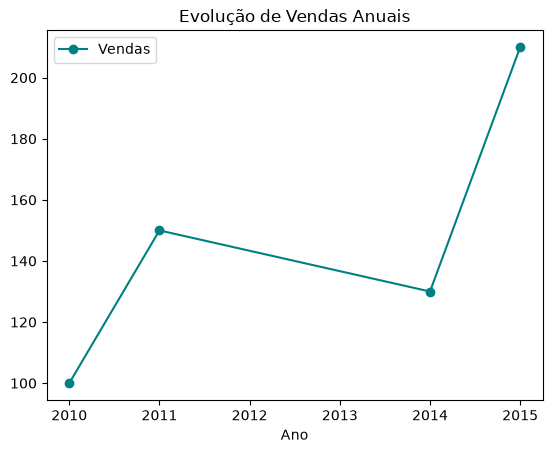

In [50]:
# Define o eixo X (Ano) e o eixo Y (Vendas)
df.plot(x='Ano', y='Vendas', kind='line', marker='o', color='teal')
plt.title('Evolução de Vendas Anuais')
plt.show()

In [51]:
df_produtos = pd.DataFrame({'Produto': ['A', 'B', 'C'], 'Qtd': [45, 80, 60]})
df_produtos

,Produto,Qtd
0,A,45
1,B,80
2,C,60


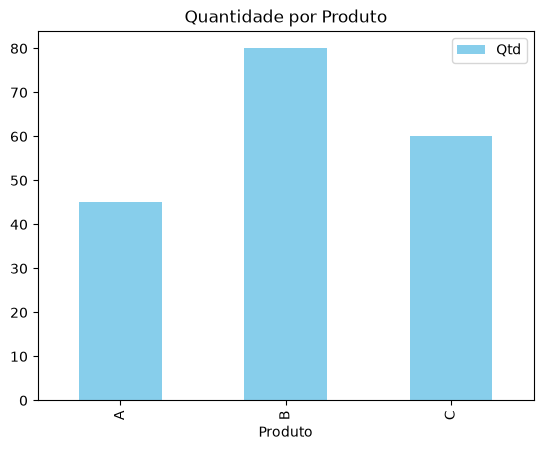

In [52]:
# Cria barras verticais. Use 'barh' para barras horizontais.
df_produtos.plot(x='Produto', y='Qtd', kind='bar', color='skyblue')
plt.title('Quantidade por Produto')
plt.show()

In [55]:
df_lojas = pd.DataFrame({'Clientes':["A", "B", "C", "D"], 'Faturamento': [1500, 2400, 4000, 900]})
df_lojas

,Clientes,Faturamento
0,A,1500
1,B,2400
2,C,4000
3,D,900


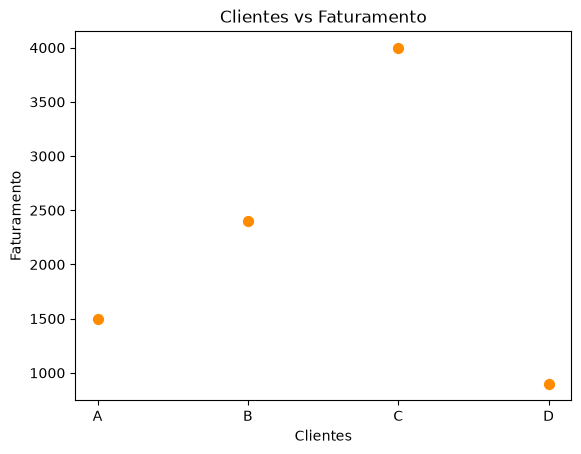

In [56]:
# Cruza duas colunas numéricas (obrigatório passar x e y)
df_lojas.plot(x='Clientes', y='Faturamento', kind='scatter', color='darkorange', s=50)
plt.title('Clientes vs Faturamento')
plt.show()

In [57]:
df_idades = pd.DataFrame({'Idade': [22, 25, 25, 30, 35, 40, 42, 45, 50, 55, 60]})
df_idades

,Idade
0,22
1,25
2,25
3,30
4,35
5,40
6,42
7,45
8,50
9,55


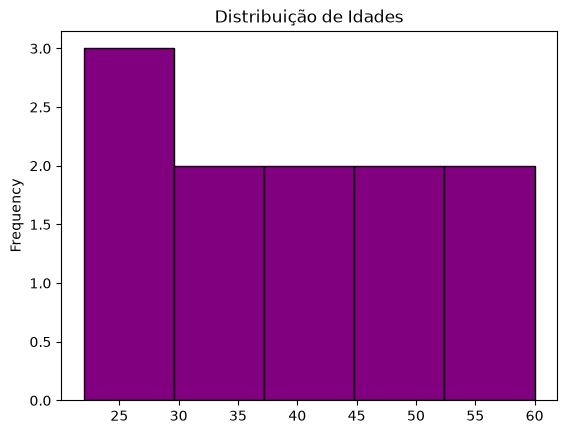

In [58]:
# Mostra quantas vezes os números aparecem agrupados em blocos (bins)
df_idades['Idade'].plot(kind='hist', bins=5, edgecolor='black', color='purple')
plt.title('Distribuição de Idades')
plt.show()

In [59]:
plt.close("all")

In [60]:
ts = pd.Series(np.random.randn(1000), index=pd.date_range("1/1/2000", periods=1000))
ts

2000-01-01   -0.226592
2000-01-02   -0.457259
2000-01-03    0.343454
2000-01-04    0.512417
2000-01-05   -0.471602
                ...   
2002-09-22    0.268571
2002-09-23   -0.191116
2002-09-24    0.186608
2002-09-25   -0.542057
2002-09-26   -0.074530
Freq: D, Length: 1000, dtype: float64

In [61]:
ts = ts.cumsum()
ts

2000-01-01    -0.226592
2000-01-02    -0.683851
2000-01-03    -0.340397
2000-01-04     0.172020
2000-01-05    -0.299582
                ...    
2002-09-22    60.675279
2002-09-23    60.484163
2002-09-24    60.670771
2002-09-25    60.128714
2002-09-26    60.054184
Freq: D, Length: 1000, dtype: float64

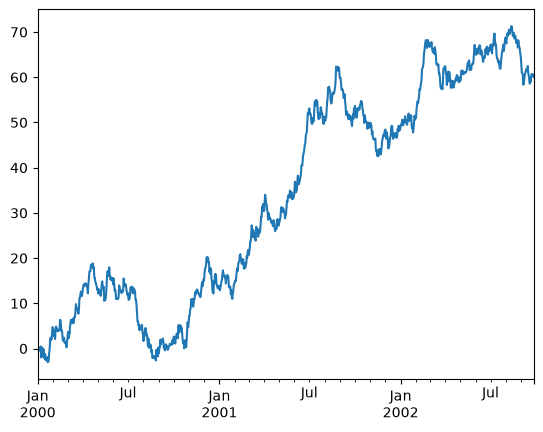

In [62]:
ts.plot();

In [63]:
df = pd.DataFrame(
    np.random.randn(1000, 4), index=ts.index, columns=["A", "B", "C", "D"]
)
df

,A,B,C,D
2000-01-01,1.628108,-0.258536,0.568727,0.440511
2000-01-02,-0.090641,-0.466283,0.142648,-0.781754
2000-01-03,-1.494311,0.069905,0.699763,0.678953
2000-01-04,-0.050560,-1.073760,0.086672,0.757959
2000-01-05,0.541074,0.392374,-3.126180,-0.402848
...,...,...,...,...
2002-09-22,-0.172908,-1.251250,-1.942415,-1.200184
2002-09-23,2.158259,1.503711,-1.572297,0.263673
2002-09-24,-0.760415,-0.466779,-1.115915,0.508342
2002-09-25,-2.627882,-0.584713,0.613634,-0.989009


In [64]:
df = df.cumsum()
df

,A,B,C,D
2000-01-01,1.628108,-0.258536,0.568727,0.440511
2000-01-02,1.537467,-0.724819,0.711375,-0.341242
2000-01-03,0.043156,-0.654913,1.411138,0.337711
2000-01-04,-0.007404,-1.728674,1.497810,1.095670
2000-01-05,0.533670,-1.336300,-1.628370,0.692821
...,...,...,...,...
2002-09-22,28.060597,-6.087807,-46.902303,4.377785
2002-09-23,30.218856,-4.584097,-48.474600,4.641458
2002-09-24,29.458441,-5.050876,-49.590515,5.149800
2002-09-25,26.830559,-5.635589,-48.976881,4.160791


In [65]:
plt.figure();

<Figure size 640x480 with 0 Axes>

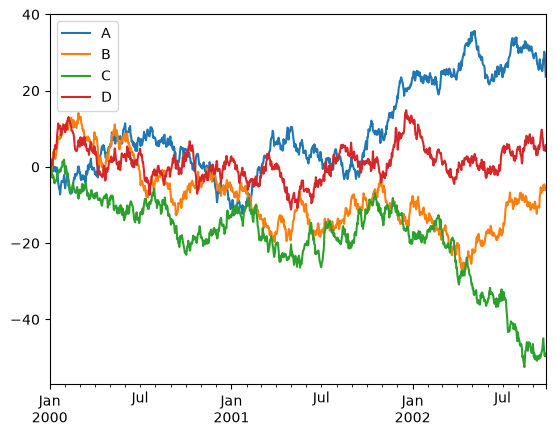

In [68]:
df.plot();
plt.legend(loc='best');

## Importando dados específicos
Ao importar os dados é possível ainda selecionar apenas algumas linhas ou até colunas específicas, veja os exemplos abaixo:

In [204]:
#É possível salvar apenas as 5 primeiras linhas ou quantas linhas desejarmos
dados_primeiras_linhas = pd.read_csv(url,nrows=5)
dados_primeiras_linhas #Exibindo df completo

,ID_Cliente,Idade,Grau_escolaridade,Estado_civil,Tamanho_familia,Categoria_de_renda,Ocupacao,Anos_empregado,Rendimento_anual,Tem_carro,Moradia
0,5008804,32,Ensino superior,União-estável,2,Empregado,Outro,12,427500.0,1,Apartamento alugado
1,5008805,32,Ensino superior,União-estável,2,Empregado,Outro,12,427500.0,1,Apartamento alugado
2,5008806,58,Ensino médio,Casado,2,Empregado,Segurança,3,112500.0,1,Casa/apartamento próprio
3,5008808,52,Ensino médio,Solteiro,1,Associado comercial,Vendas,8,270000.0,0,Casa/apartamento próprio
4,5008809,52,Ensino médio,Solteiro,1,Associado comercial,Vendas,8,270000.0,0,Casa/apartamento próprio


In [10]:
# É possível ainda selecionar as colunas desejadas
dados_selecao = pd.read_csv(url, usecols=['Id', 'Year_Birth', 'Income'])
dados_selecao #Exibindo df completo

In [12]:
#É possivel selecionar as colunas tanto pelo nome quando pelo index
dados_selecao = pd.read_csv(url, usecols=[0,1,4]) 
dados_selecao #Exibindo df completo

In [ ]:
#Caso queira pegar um arquivo do tipo excel que esteja em um link basta fazer o mesmo que no .csv colocar a url no lugar do arquivo 
url = 'https://github.com/alura-cursos/Pandas/blob/main/emissoes_CO2.xlsx?raw=True'
dados_co2 = pd.read_excel(url)
dados_co2 #Exibindo df completo

In [ ]:
pd.ExcelFile(url).sheet_names #comando para verificar quais planilhas o arquivo excel possui

In [ ]:
chave = '1pvBoLyX8kP0TjtUbadVMGdTl4yzm6bHMThhPiqCVtpw'
url=f'https://docs.google.com/spreadsheets/d/{chave}/gviz/tq?tqx=out:csv&sheet'
co2_per_capita = pd.read_csv(url)

In [ ]:
co2_per_capita.to_csv('co2_per_capita.csv', index = False, sep = ';')
co2_per_capita

## Pegando informações de um JSON para colocar em um DataFrame

In [14]:
dados_frutas = requests.get('https://fruityvice.com/api/fruit/all') #Pegando uma url através do get request
dados_frutas #Exibindo a resposta

<Response [200]>

In [15]:
resultado = json.loads(dados_frutas.text) #pegando a resposta do get para um json
resultado #exibindo o JSON

[{'name': 'Persimmon',
  'id': 52,
  'family': 'Ebenaceae',
  'order': 'Rosales',
  'genus': 'Diospyros',
  'nutritions': {'calories': 81,
   'fat': 0.0,
   'sugar': 18.0,
   'carbohydrates': 18.0,
   'protein': 0.0}},
 {'name': 'Strawberry',
  'id': 3,
  'family': 'Rosaceae',
  'order': 'Rosales',
  'genus': 'Fragaria',
  'nutritions': {'calories': 29,
   'fat': 0.4,
   'sugar': 5.4,
   'carbohydrates': 5.5,
   'protein': 0.8}},
 {'name': 'Banana',
  'id': 1,
  'family': 'Musaceae',
  'order': 'Zingiberales',
  'genus': 'Musa',
  'nutritions': {'calories': 96,
   'fat': 0.2,
   'sugar': 17.2,
   'carbohydrates': 22.0,
   'protein': 1.0}},
 {'name': 'Tomato',
  'id': 5,
  'family': 'Solanaceae',
  'order': 'Solanales',
  'genus': 'Solanum',
  'nutritions': {'calories': 74,
   'fat': 0.2,
   'sugar': 2.6,
   'carbohydrates': 3.9,
   'protein': 0.9}},
 {'name': 'Pear',
  'id': 4,
  'family': 'Rosaceae',
  'order': 'Rosales',
  'genus': 'Pyrus',
  'nutritions': {'calories': 57,
   'fat': 

In [16]:
df_normalizado = pd.json_normalize(resultado) #Pegando um JSON para um df usando pandas
df_normalizado #Exibindo dataframe completo.

,name,id,family,order,genus,nutritions.calories,nutritions.fat,nutritions.sugar,nutritions.carbohydrates,nutritions.protein
0,Persimmon,52,Ebenaceae,Rosales,Diospyros,81,0.00,18.00,18.00,0.00
1,Strawberry,3,Rosaceae,Rosales,Fragaria,29,0.40,5.40,5.50,0.80
2,Banana,1,Musaceae,Zingiberales,Musa,96,0.20,17.20,22.00,1.00
3,Tomato,5,Solanaceae,Solanales,Solanum,74,0.20,2.60,3.90,0.90
4,Pear,4,Rosaceae,Rosales,Pyrus,57,0.10,10.00,15.00,0.40
5,Durian,60,Malvaceae,Malvales,Durio,147,5.30,6.75,27.10,1.50
6,Blackberry,64,Rosaceae,Rosales,Rubus,40,0.40,4.50,9.00,1.30
7,Lingonberry,65,Ericaceae,Ericales,Vaccinium,50,0.34,5.74,11.30,0.75
8,Kiwi,66,Actinidiaceae,Struthioniformes,Apteryx,61,0.50,9.00,15.00,1.10
9,Lychee,67,Sapindaceae,Sapindales,Litchi,66,0.44,15.00,17.00,0.80


## Usando Banco de dados com Pandas
Executaremos agora um comando para criar uma conexão com um banco de dados SQLite temporário que roda 100% dentro da memória RAM do seu computador.
<ul>
    <li>Primeiro temos `create_engine(...)` uma função da biblioteca SQLAlchemy (a ferramenta de conexão padrão usada pelo Pandas) que funciona como a "ponte" ou o "tradutor" entre o seu código Python e o banco de dados. É ela quem gerencia o envio dos dados do seu DataFrame para as tabelas do banco.
    </li>
    <li>
        Depois `'sqlite://'` temos a string que indica o driver do banco de dados que será usado. Neste caso o SQLite é um banco de dados leve, que não precisa de servidor, usuário ou senha instalados na máquina — ele já vem nativo no Python.
    </li>
    <li>Por último temos `'/:memory:'` (O segredo do comando) que em vez de salvar as tabelas em um arquivo físico no seu disco rígido (como banco.db), diz ao sistema para criar um banco de dados "fantasma" dentro da memória RAM.
    </li>
</ul>


In [127]:
engine = create_engine('sqlite:///:memory:')# Criando uma conexão conexão com um banco SQLite (ou MySQL, PostgreSQL, etc.)

In [128]:
url = 'https://raw.githubusercontent.com/alura-cursos/Pandas/main/clientes_banco.csv'
dados = pd.read_csv(url)
dados

,ID_Cliente,Idade,Grau_escolaridade,Estado_civil,Tamanho_familia,Categoria_de_renda,Ocupacao,Anos_empregado,Rendimento_anual,Tem_carro,Moradia
0,5008804,32,Ensino superior,União-estável,2,Empregado,Outro,12,427500.0,1,Apartamento alugado
1,5008805,32,Ensino superior,União-estável,2,Empregado,Outro,12,427500.0,1,Apartamento alugado
2,5008806,58,Ensino médio,Casado,2,Empregado,Segurança,3,112500.0,1,Casa/apartamento próprio
3,5008808,52,Ensino médio,Solteiro,1,Associado comercial,Vendas,8,270000.0,0,Casa/apartamento próprio
4,5008809,52,Ensino médio,Solteiro,1,Associado comercial,Vendas,8,270000.0,0,Casa/apartamento próprio
...,...,...,...,...,...,...,...,...,...,...,...
438458,6840104,62,Ensino médio,Divorciado,1,Pensionista,Outro,0,135000.0,0,Casa/apartamento próprio
438459,6840222,43,Ensino médio,Solteiro,1,Empregado,Construção Civil,8,103500.0,0,Casa/apartamento próprio
438460,6841878,22,Ensino superior,Solteiro,1,Associado comercial,Vendas,1,54000.0,0,Mora com os pais
438461,6842765,59,Ensino médio,Casado,2,Pensionista,Outro,0,72000.0,0,Casa/apartamento próprio


## Salvando o conteúdo de um DataFrame do Pandas diretamente em uma tabela de banco de dados

**1.** `dados.to_sql(...)`: É o método do Pandas que converte a estrutura do DataFrame em comandos SQL de inserção (INSERT INTO) e os executa no banco de dados.

**2.** `'clientes'`: É o nome da tabela que será criada ou modificada dentro do seu banco de dados. Se a tabela já existir, o Pandas tentará inserir os dados nela.

**3.** `engine`: É o motor de conexão com o banco de dados. Ele armazena as credenciais e o endereço (como usuário, senha, host, porta e nome do banco). Geralmente ele é criado antes usando a biblioteca SQLAlchemy:
python

**4.** `index=False`: Por padrão, o Pandas trata o índice do DataFrame (aqueles números 0, 1, 2... ou nomes na lateral esquerda) como se fossem uma coluna comum e tenta salvá-los no banco de dados.
• `index=False`: Diz ao Pandas para ignorar o índice e salvar apenas as colunas de dados reais (como Nome, Idade, Email, etc.).
• Se você esquecer de colocar isso: O banco de dados criará uma coluna extra chamada index ou level_0, o que costuma desorganizar tabelas de produção.

**Um parâmetro extra que você provavelmente vai precisar: if_exists**

Por padrão, se a tabela `'clientes'` já existir no seu banco de dados, esse código vai dar um erro. Para evitar isso, você deve adicionar o parâmetro if_exists:
* `if_exists='append'`: Adiciona os novos dados no final da tabela que já existe.
* `if_exists='replace'`: Apaga a tabela antiga inteira e cria uma nova do zero com os novos dados.


In [129]:
dados.to_sql('clientes', engine, index=False)

438463

O comando `inspector = inspect(engine)` serve para criar um objeto capaz de **"olhar por dentro" do seu banco de dados** e ler a estrutura dele (os metadados), sem que você precise rodar comandos SQL manuais para isso.

In [130]:
inspector = inspect(engine)

In [131]:
#Mostrando todas as tabelas do banco de dados
print(inspector.get_table_names())

['clientes']


Agora vamos fazer uma requisições para esse banco de dados

In [132]:
query = 'SELECT * FROM clientes WHERE Categoria_de_renda="Empregado"'
empregados = pd.read_sql(query, engine)
empregados

,ID_Cliente,Idade,Grau_escolaridade,Estado_civil,Tamanho_familia,Categoria_de_renda,Ocupacao,Anos_empregado,Rendimento_anual,Tem_carro,Moradia
0,5008804,32,Ensino superior,União-estável,2,Empregado,Outro,12,427500.0,1,Apartamento alugado
1,5008805,32,Ensino superior,União-estável,2,Empregado,Outro,12,427500.0,1,Apartamento alugado
2,5008806,58,Ensino médio,Casado,2,Empregado,Segurança,3,112500.0,1,Casa/apartamento próprio
3,5008815,46,Ensino superior,Casado,2,Empregado,Contabilidade,2,270000.0,1,Casa/apartamento próprio
4,5112956,46,Ensino superior,Casado,2,Empregado,Contabilidade,2,270000.0,1,Casa/apartamento próprio
...,...,...,...,...,...,...,...,...,...,...,...
226054,6837905,43,Ensino médio,Casado,3,Empregado,Outro,7,355050.0,1,Casa/apartamento próprio
226055,6837906,43,Ensino médio,Casado,3,Empregado,Outro,7,355050.0,1,Casa/apartamento próprio
226056,6839936,34,Ensino médio,Casado,3,Empregado,Construção Civil,5,135000.0,1,Casa/apartamento próprio
226057,6840222,43,Ensino médio,Solteiro,1,Empregado,Construção Civil,8,103500.0,0,Casa/apartamento próprio


In [133]:
#Adicionando outra tabela ao banco de dados
empregados.to_sql('empregados', con=engine, index=False)

226059

In [134]:
#Mostrando todas as tabelas do banco de dados
inspector = inspect(engine)
print(inspector.get_table_names())

['clientes', 'empregados']


O comando `pd.read_sql_table('clientes', engine)` serve para trazer uma tabela inteira do banco de dados diretamente para um DataFrame do Pandas, sem que você precise escrever nenhuma linha de código SQL (como `SELECT * FROM...`).

In [135]:
pd.read_sql_table('clientes', engine)

,ID_Cliente,Idade,Grau_escolaridade,Estado_civil,Tamanho_familia,Categoria_de_renda,Ocupacao,Anos_empregado,Rendimento_anual,Tem_carro,Moradia
0,5008804,32,Ensino superior,União-estável,2,Empregado,Outro,12,427500.0,1,Apartamento alugado
1,5008805,32,Ensino superior,União-estável,2,Empregado,Outro,12,427500.0,1,Apartamento alugado
2,5008806,58,Ensino médio,Casado,2,Empregado,Segurança,3,112500.0,1,Casa/apartamento próprio
3,5008808,52,Ensino médio,Solteiro,1,Associado comercial,Vendas,8,270000.0,0,Casa/apartamento próprio
4,5008809,52,Ensino médio,Solteiro,1,Associado comercial,Vendas,8,270000.0,0,Casa/apartamento próprio
...,...,...,...,...,...,...,...,...,...,...,...
438458,6840104,62,Ensino médio,Divorciado,1,Pensionista,Outro,0,135000.0,0,Casa/apartamento próprio
438459,6840222,43,Ensino médio,Solteiro,1,Empregado,Construção Civil,8,103500.0,0,Casa/apartamento próprio
438460,6841878,22,Ensino superior,Solteiro,1,Associado comercial,Vendas,1,54000.0,0,Mora com os pais
438461,6842765,59,Ensino médio,Casado,2,Pensionista,Outro,0,72000.0,0,Casa/apartamento próprio


In [136]:
from sqlalchemy import text
query = "DELETE FROM clientes WHERE ID_Cliente=5008804;"
with engine.connect() as conn:
    conn.execute(text(query))

In [39]:
query = 'UPDATE clientes SET Grau_escolaridade="Ensino superior" WHERE ID_Cliente=5008808'
with engine.connect() as conn:
    conn.execute(text(query))

In [40]:
query = 'INSERT INTO clientes (ID_Cliente, Idade, Grau_escolaridade, '\
        'Estado_civil, Tamanho_familia, Categoria_de_renda, Ocupacao, ' \
        'Anos_empregado, Rendimento_anual, Tem_carro, Moradia) ' \
        'VALUES (6850985, 33, "Doutorado", "Solteiro", 1, "Empregado", "TI", ' \
        '2, 290000, 0, "Casa/apartamento próprio")'
with engine.connect() as conn:
    conn.execute(text(query))

## Exportando dados para **`.CSV`**

In [69]:
df = pd.DataFrame(np.random.randint(0, 5, (10, 5)))
df.to_csv("foo.csv")

## Importando e Exportando para outros formatos de arquivo

### Parquet

In [70]:
df.to_parquet("foo.parquet")

In [71]:
pd.read_parquet("foo.parquet")

,0,1,2,3,4
0,2,1,3,4,3
1,4,4,4,2,1
2,3,1,4,1,0
3,1,4,4,2,0
4,1,4,0,2,3
5,4,1,3,2,1
6,1,1,0,4,2
7,2,1,1,4,0
8,1,3,0,4,1
9,1,0,0,2,3


### Excel

In [72]:
df.to_excel("foo.xlsx", sheet_name="Sheet1")

In [73]:
pd.read_excel("foo.xlsx", "Sheet1", index_col=None, na_values=["NA"])

,Unnamed: 0,0,1,2,3,4
0,0,2,1,3,4,3
1,1,4,4,4,2,1
2,2,3,1,4,1,0
3,3,1,4,4,2,0
4,4,1,4,0,2,3
5,5,4,1,3,2,1
6,6,1,1,0,4,2
7,7,2,1,1,4,0
8,8,1,3,0,4,1
9,9,1,0,0,2,3
